# Unknown / fluctuating source intensities as a nuisance parameter

The contrast $r_c = I_\mathrm{mid}/I_\mathrm{out}$ is co-estimated rather than
known. With intensities renormalised so $\sum_v I_v = 1$, the total photon
budget is fixed and $r_c$ only reallocates it between the depth (middle)
source and the two width sources (`target_point_source_idx = 0`).

For each estimator (mode-sorting FI and QFI) we compare three bounds on the
width/depth parameters $\theta = (\delta x, \delta z)$:

- **known** intensity &mdash; $(J^{-1}_{\theta\theta})$, invert the
  $\theta\theta$ block (`*_spatial`);
- **unknown / marginal** &mdash; the Schur complement
  $(J_{\theta\theta} - J_{\theta\eta} J_{\eta\eta}^{-1} J_{\eta\theta})^{-1}$,
  $r_c$ marginalised as a nuisance (`*_nuis`);
- the full $3\times3$ inverse (`*_inv`), whose $[2,2]$ entry is
  $\mathrm{Var}(r_c)$.

All font sizes come from `latexify()`; individual figures vary colour only.

In [1]:
import glob
import re

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.ticker import FuncFormatter, NullFormatter

from rayfish.visualize_helpers import latexify

latexify()
FORMAT = "pdf"

In [2]:
%matplotlib inline

## Load data

In [3]:
# Read the contrasts from whatever simulation output is on disk.
contrasts = sorted(
    float(re.search(r"qfi_(\d+\.\d+)\.npy", f).group(1))  # type: ignore
    for f in glob.glob("qfi_*.npy")
    if "_inv_" not in f and "dform" not in f
)

coords = np.load("coordinates.npy")
p_range = -coords[0, :, 6]  # depth displacement delta z / z_R
x_range = coords[:, 0, 2]  # transverse coordinate; width delta x = sqrt(2) * x_range

# Full 3x3 CRB (theta and r_c jointly); its [2,2] block is Var(r_c).
fis_inv = [np.load(f"fi_ms_inv_{c:.2f}.npy") for c in contrasts]
qfis_inv = [np.load(f"qfi_inv_{c:.2f}.npy") for c in contrasts]

# Geometry 2x2 bounds: known (theta-theta inverse) and marginal (Schur).
fis_known = [np.load(f"fi_ms_inv_spatial_{c:.2f}.npy") for c in contrasts]
fis_marg = [np.load(f"fi_ms_inv_nuis_{c:.2f}.npy") for c in contrasts]
qfis_known = [np.load(f"qfi_inv_spatial_{c:.2f}.npy") for c in contrasts]
qfis_marg = [np.load(f"qfi_inv_nuis_{c:.2f}.npy") for c in contrasts]
contrasts

[0.2,
 0.23,
 0.28,
 0.32,
 0.38,
 0.45,
 0.53,
 0.62,
 0.72,
 0.85,
 1.0,
 1.17,
 1.38,
 1.62,
 1.9,
 2.24,
 2.63,
 3.09,
 3.62,
 4.26,
 5.0]

In [4]:
# Helpers and shared plotting furniture.
c_arr = np.array(contrasts)
baseline = contrasts.index(1.0)  # r_c = 1 (equal brightness)


def _idx(arr: np.ndarray, val: float) -> int:
    """Grid index nearest to a target coordinate value."""
    return int(np.argmin(np.abs(arr - val)))


def _series(arrays: list[np.ndarray], ix: int, iz: int, a: int, b: int) -> np.ndarray:
    """Bound component (a, b) at a fixed geometry, one value per contrast."""
    return np.array([A[ix, iz, a, b] for A in arrays])


# Clean single-parameter signals (small orthogonal coordinate) and one
# representative deep sub-Rayleigh geometry for the vs-contrast figures.
iz_w = _idx(p_range, 0.2)
ix_d = _idx(x_range, 0.3)
ix0 = _idx(x_range, 0.3 / np.sqrt(2))
iz0 = _idx(p_range, 0.3)

# Plain-number log-axis ticks either side of r_c = 1.
r_ticks = [0.2, 0.5, 1, 2, 5]
_g = FuncFormatter(lambda v, _: f"{v:g}")

## Consistency checks: LL-form vs D-form QFIM

`qfi_*.npy` is the real part of the SLD covariance
$\mathrm{Tr}(R\, G L_a G L_b G)$ (LL-form); `qfi_dform_*.npy` is the
independent D-form contraction $\mathrm{Re\,Tr}(L_a G\, \partial_b\rho\, G)$.
The two must agree to float precision (they differ only in which trace is
evaluated). `compat_*.npy` is the imaginary part
$D_{ab} = \tfrac{1}{2i}\mathrm{Tr}(\rho\,[\Lambda_a, \Lambda_b])$ and must be
antisymmetric &mdash; a direct regression on the contraction ordering.

In [ ]:
# Regression: two independent QFIM contractions + compatibility structure.
qfis = [np.load(f"qfi_{c:.2f}.npy") for c in contrasts]
qfis_dform = [np.load(f"qfi_dform_{c:.2f}.npy") for c in contrasts]
compats = [np.load(f"compat_{c:.2f}.npy") for c in contrasts]

scale = max(np.abs(h).max() for h in qfis)
form_err = (
    max(np.abs(h - d).max() for h, d in zip(qfis, qfis_dform, strict=False)) / scale
)
sym_err = max(np.abs(h - h.swapaxes(-1, -2)).max() for h in qfis) / scale
d_scale = max(np.abs(d).max() for d in compats)
asym_err = max(np.abs(d + d.swapaxes(-1, -2)).max() for d in compats) / d_scale

# print(f"LL-form vs D-form QFIM     (rel): {form_err:.3e}")
# print(f"QFIM symmetry              (rel): {sym_err:.3e}")
# print(f"compatibility antisymmetry (rel): {asym_err:.3e}")
# assert form_err < 1e-10, "LL-form and D-form QFIM disagree"
# assert asym_err < 1e-10, "compatibility matrix is not antisymmetric"

LL-form vs D-form QFIM     (rel): 1.854e-12
QFIM symmetry              (rel): 4.732e-13
compatibility antisymmetry (rel): 1.898e-11


## A. Nuisance-adjusted CRB vs contrast (known vs unknown intensity)

Width ($\delta x$) and depth ($\delta z$) Cram\'er-Rao bounds vs contrast at a
fixed deep sub-Rayleigh geometry. **Colour** = estimator (QFI red, MS blue);
**line style** = intensity assumption (solid known, dashed unknown/marginal).
The solid&ndash;dashed gap is the cost of not knowing the brightness &mdash;
expected small sub-Rayleigh. Dashed vertical line = equal brightness.

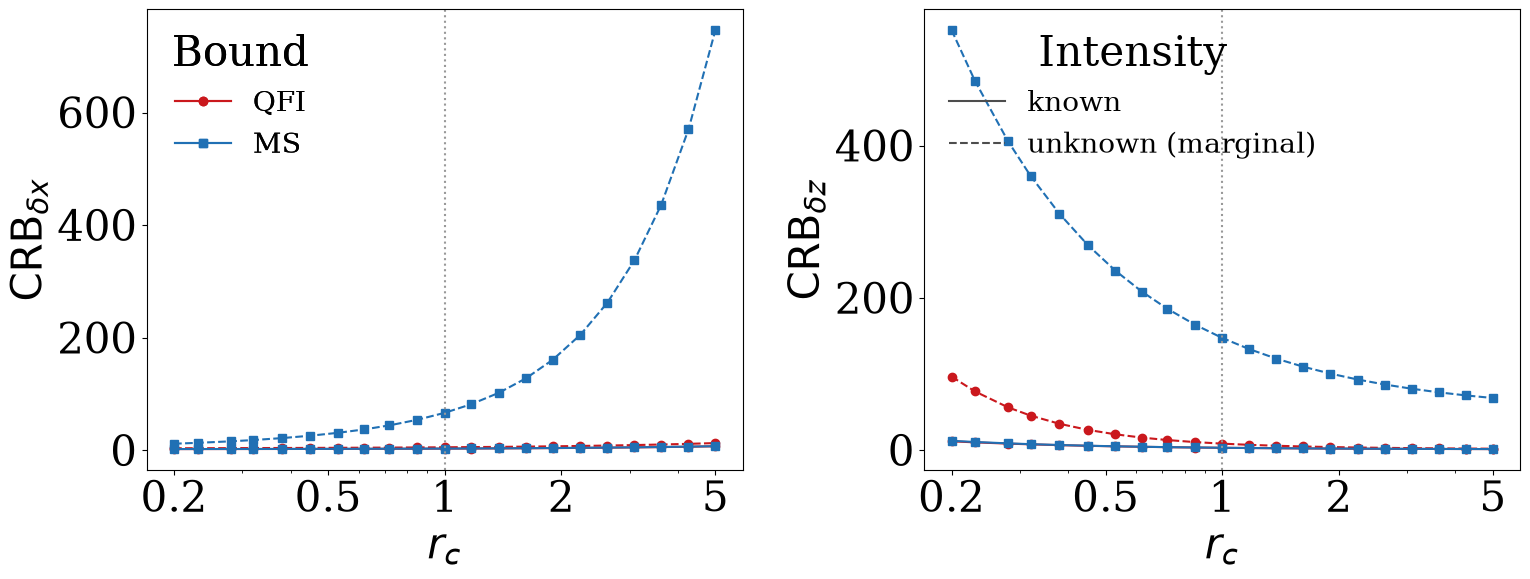

In [6]:
c_qfi = plt.cm.Reds(0.75)  # type: ignore
c_ms = plt.cm.Blues(0.75)  # type: ignore

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, ab, ylab in [
    (axes[0], 0, r"$\mathrm{CRB}_{\delta x}$"),
    (axes[1], 1, r"$\mathrm{CRB}_{\delta z}$"),
]:
    ax.plot(c_arr, _series(qfis_known, ix0, iz0, ab, ab), "o-", color=c_qfi)
    ax.plot(c_arr, _series(qfis_marg, ix0, iz0, ab, ab), "o--", color=c_qfi)
    ax.plot(c_arr, _series(fis_known, ix0, iz0, ab, ab), "s-", color=c_ms)
    ax.plot(c_arr, _series(fis_marg, ix0, iz0, ab, ab), "s--", color=c_ms)
    ax.axvline(1.0, color="0.6", ls=":", lw=1.5)
    ax.set_xscale("log")
    ax.set_xticks(r_ticks)
    ax.xaxis.set_major_formatter(_g)
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(r"$r_c$")
    ax.set_ylabel(ylab)

_l1 = axes[0].legend(
    [
        Line2D([], [], color=c_qfi, ls="-", marker="o"),
        Line2D([], [], color=c_ms, ls="-", marker="s"),
    ],
    ["QFI", "MS"],
    title="Bound",
    frameon=False,
    loc="upper left",
)
axes[0].add_artist(_l1)
axes[1].legend(
    [Line2D([], [], color="0.3", ls="-"), Line2D([], [], color="0.3", ls="--")],
    ["known", "unknown (marginal)"],
    title="Intensity",
    frameon=False,
    loc="upper left",
)

fig.tight_layout()
# fig.savefig(f"nuisance_crb_vs_contrast.{FORMAT}", format=FORMAT, bbox_inches="tight")
plt.show()

## B. Mode-sorting efficiency under unknown brightness

CRB efficiency $H^{-1}/J^{-1}$ (quantum CRB over MS CRB, $\le 1$) per
parameter, computed **known** (solid) and **marginal / unknown** (dashed). If
unknown brightness is nearly free to marginalise, the two curves overlap and
both stay flat and close to $1$: MS still attains the nuisance-adjusted
quantum limit.

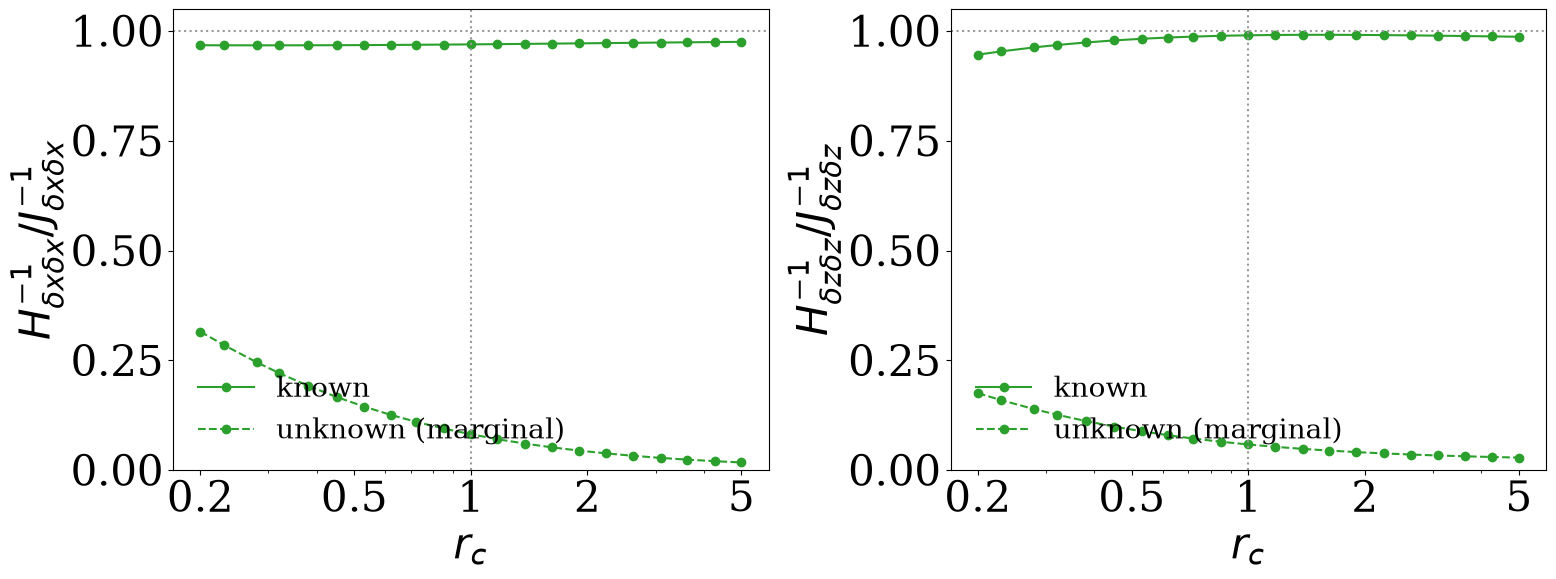

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for ax, ab, ylab in [
    (axes[0], 0, r"$H^{-1}_{\delta x \delta x}/J^{-1}_{\delta x \delta x}$"),
    (axes[1], 1, r"$H^{-1}_{\delta z \delta z}/J^{-1}_{\delta z \delta z}$"),
]:
    eff_known = _series(qfis_known, ix0, iz0, ab, ab) / _series(
        fis_known, ix0, iz0, ab, ab
    )
    eff_marg = _series(qfis_marg, ix0, iz0, ab, ab) / _series(
        fis_marg, ix0, iz0, ab, ab
    )
    ax.plot(c_arr, eff_known, "o-", color="tab:green", label="known")
    ax.plot(c_arr, eff_marg, "o--", color="tab:green", label="unknown (marginal)")
    ax.axhline(1.0, color="0.6", ls=":", lw=1.5)
    ax.axvline(1.0, color="0.6", ls=":", lw=1.5)
    ax.set_xscale("log")
    ax.set_xticks(r_ticks)
    ax.xaxis.set_major_formatter(_g)
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_ylim(0.0, 1.05)
    ax.set_xlabel(r"$r_c$")
    ax.set_ylabel(ylab)
    ax.legend(frameon=False, loc="lower left")

fig.tight_layout()
# fig.savefig(f"ms_efficiency_nuisance_vs_contrast.{FORMAT}",
# format=FORMAT, bbox_inches="tight")
plt.show()

## C. Inflation of the CRB vs separation

Inflation $= \mathrm{CRB}^{\mathrm{unknown}}/\mathrm{CRB}^{\mathrm{known}} \ge 1$:
the multiplicative penalty for co-estimating brightness, vs separation, for a
few contrasts (MS bounds; QFI is analogous). Near $1$ sub-Rayleigh (geometry
and brightness scores decouple, $J_{\theta\eta}\approx0$) and rising only
toward the Rayleigh scale where the modes overlap.

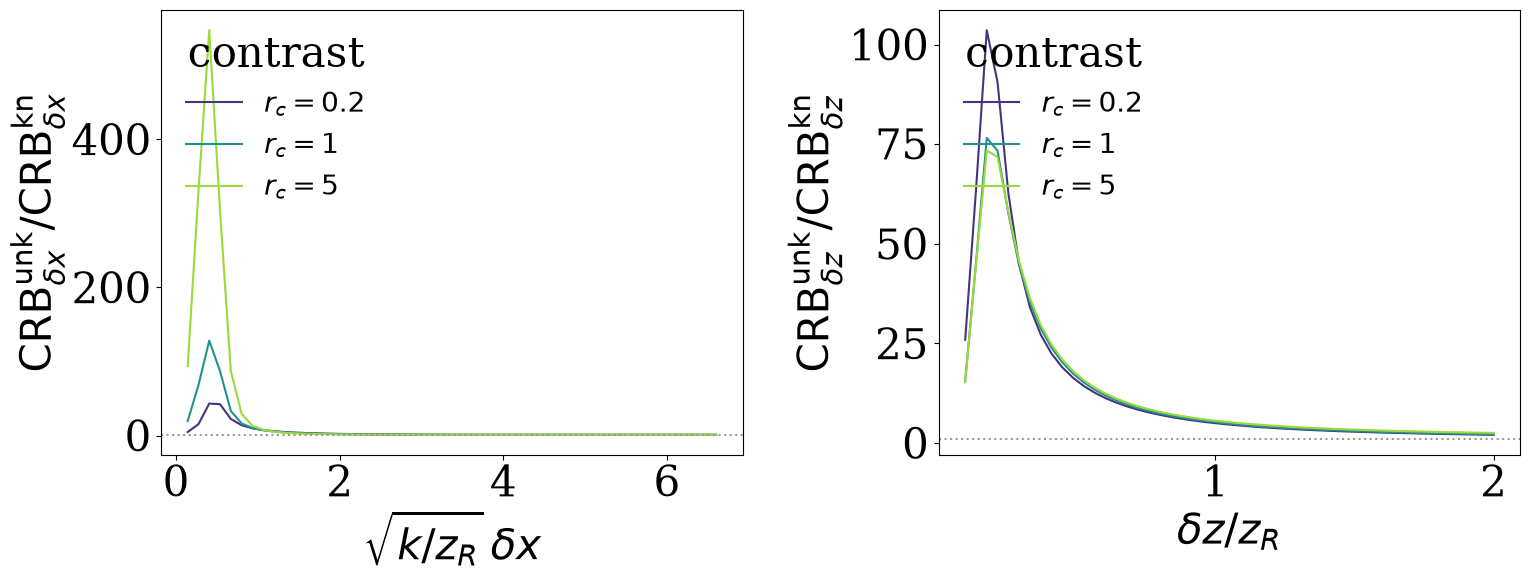

In [8]:
sel_c = [c for c in (0.2, 1.0, 5.0) if c in contrasts]
c_shades = plt.cm.viridis(np.linspace(0.15, 0.85, len(sel_c)))  # type: ignore

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))
for k, cval in enumerate(sel_c):
    j = contrasts.index(cval)
    infl_w = fis_marg[j][:, iz_w, 0, 0] / fis_known[j][:, iz_w, 0, 0]
    infl_d = fis_marg[j][ix_d, :, 1, 1] / fis_known[j][ix_d, :, 1, 1]
    axes[0].plot(
        np.sqrt(2) * x_range, infl_w, "-", color=c_shades[k], label=rf"$r_c={cval:g}$"
    )
    axes[1].plot(p_range, infl_d, "-", color=c_shades[k], label=rf"$r_c={cval:g}$")

axes[0].set_xlabel(r"$\sqrt{k/z_R}\,\delta x$")
axes[0].set_ylabel(
    r"$\mathrm{CRB}^{\mathrm{unk}}_{\delta x}/\mathrm{CRB}^{\mathrm{kn}}_{\delta x}$"
)
axes[1].set_xlabel(r"$\delta z/z_R$")
axes[1].set_ylabel(
    r"$\mathrm{CRB}^{\mathrm{unk}}_{\delta z}/\mathrm{CRB}^{\mathrm{kn}}_{\delta z}$"
)
for ax in axes:
    ax.axhline(1.0, color="0.6", ls=":", lw=1.5)
    ax.legend(title="contrast", frameon=False, loc="upper left")

fig.tight_layout()
# fig.savefig(f"crb_inflation_vs_separation.{FORMAT}",
# format=FORMAT, bbox_inches="tight")
plt.show()

## D. Joint 3-parameter estimation (diagnostic)

Full joint estimate of $(\delta x, \delta z, r_c)$: diagonal CRBs from the full
$3\times3$ inverse, including the nuisance contrast itself. The $\delta x,
\delta z$ panels are the marginal (unknown-intensity) bounds; the $r_c$ panel
is a diagnostic &mdash; a finite $\mathrm{CRB}_{r_c}$ confirms the contrast
block is well-conditioned wherever the geometry marginal cost is small. Log
axes since the three scales differ.

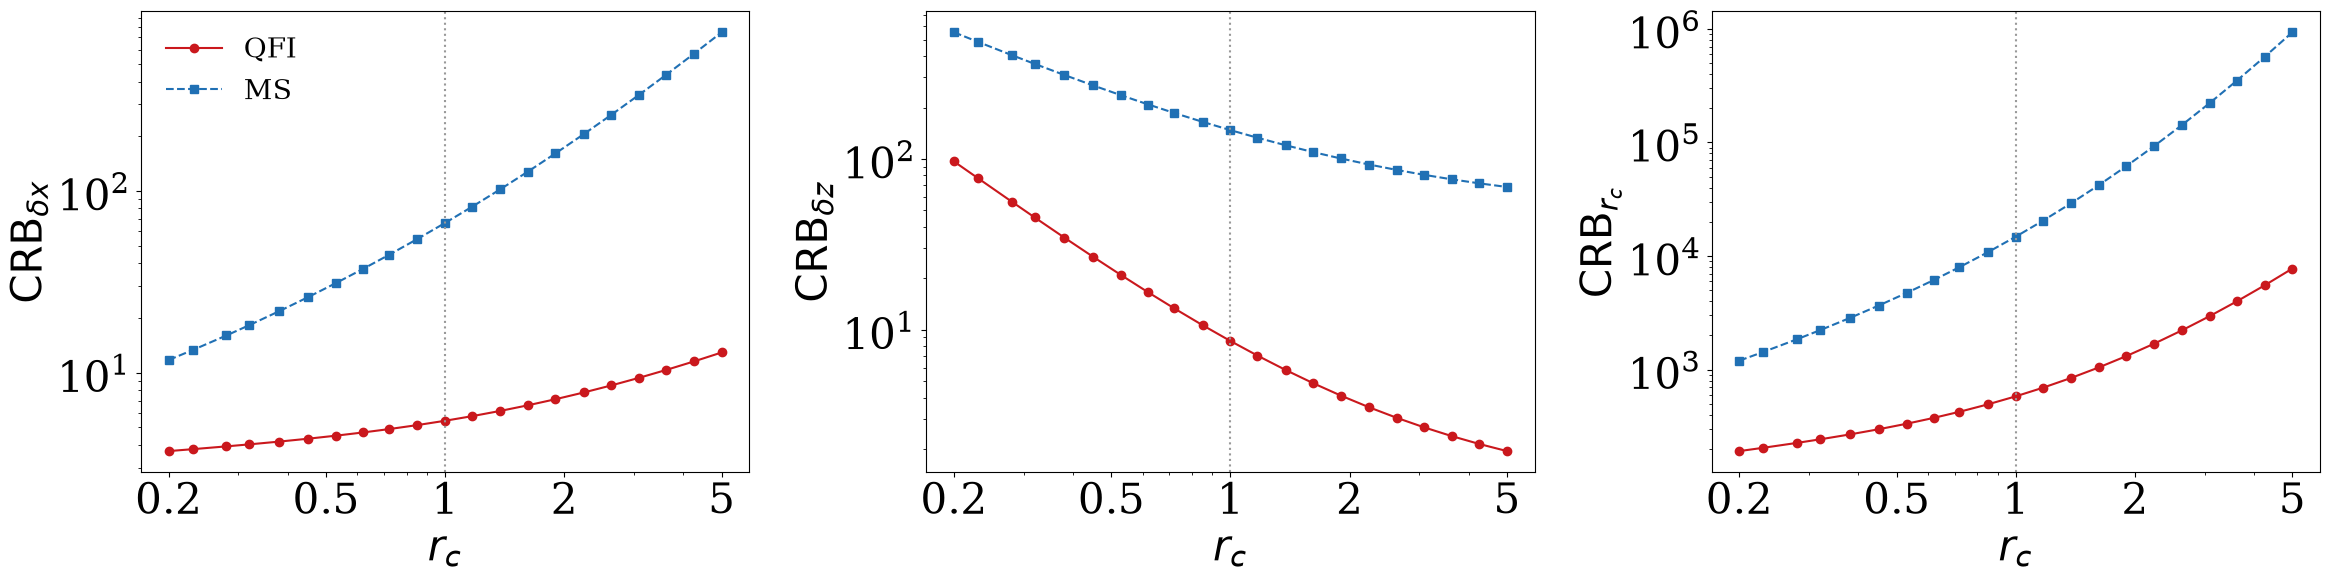

In [9]:
fig, axes = plt.subplots(
    1, 3, figsize=(24, 6.5)
)  # 8-wide panels, matching the 1x2 figs
for ax, ab, ylab in [
    (axes[0], 0, r"$\mathrm{CRB}_{\delta x}$"),
    (axes[1], 1, r"$\mathrm{CRB}_{\delta z}$"),
    (axes[2], 2, r"$\mathrm{CRB}_{r_c}$"),
]:
    ax.plot(
        c_arr,
        _series(qfis_inv, ix0, iz0, ab, ab),
        "o-",
        color=plt.cm.Reds(0.75),  # type: ignore
        label="QFI",
    )
    ax.plot(
        c_arr,
        _series(fis_inv, ix0, iz0, ab, ab),
        "s--",
        color=plt.cm.Blues(0.75),  # type: ignore
        label="MS",
    )
    ax.axvline(1.0, color="0.6", ls=":", lw=1.5)
    ax.set_xscale("log")
    ax.set_yscale("log")
    ax.set_xticks(r_ticks)
    ax.xaxis.set_major_formatter(_g)
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_xlabel(r"$r_c$")
    ax.set_ylabel(ylab)
axes[0].legend(frameon=False, loc="upper left")

fig.tight_layout()
# fig.savefig(f"joint_three_param_crb_vs_contrast.{FORMAT}",
# format=FORMAT, bbox_inches="tight")
plt.show()

## E. Incompatibility: is the marginal quantum bound attainable?

Scalar incompatibility $c = \lVert i H^{-1} D \rVert_\infty \in [0, 1]$: the
Holevo bound lies between the SLD-CRB and $(1+c)\times$ it. $c \approx 0$
means a single collective measurement can attain all SLD bounds
simultaneously, so the marginal benchmark of Figs A/B is honest; $c = O(1)$
means part of the QFI&ndash;MS gap is unreachable by *any* measurement. Two
variants: the **full** set $(\delta x, \delta z, r_c)$, and the **effective
scores** $L_a^{\mathrm{eff}} = L_a - (H_{ar}/H_{rr}) L_r$ on the geometry
pair with $r_c$ marginalised &mdash; the latter is what gates joint
attainment of the marginal bounds (and the adapted POVM of Spec 6 Part 2).

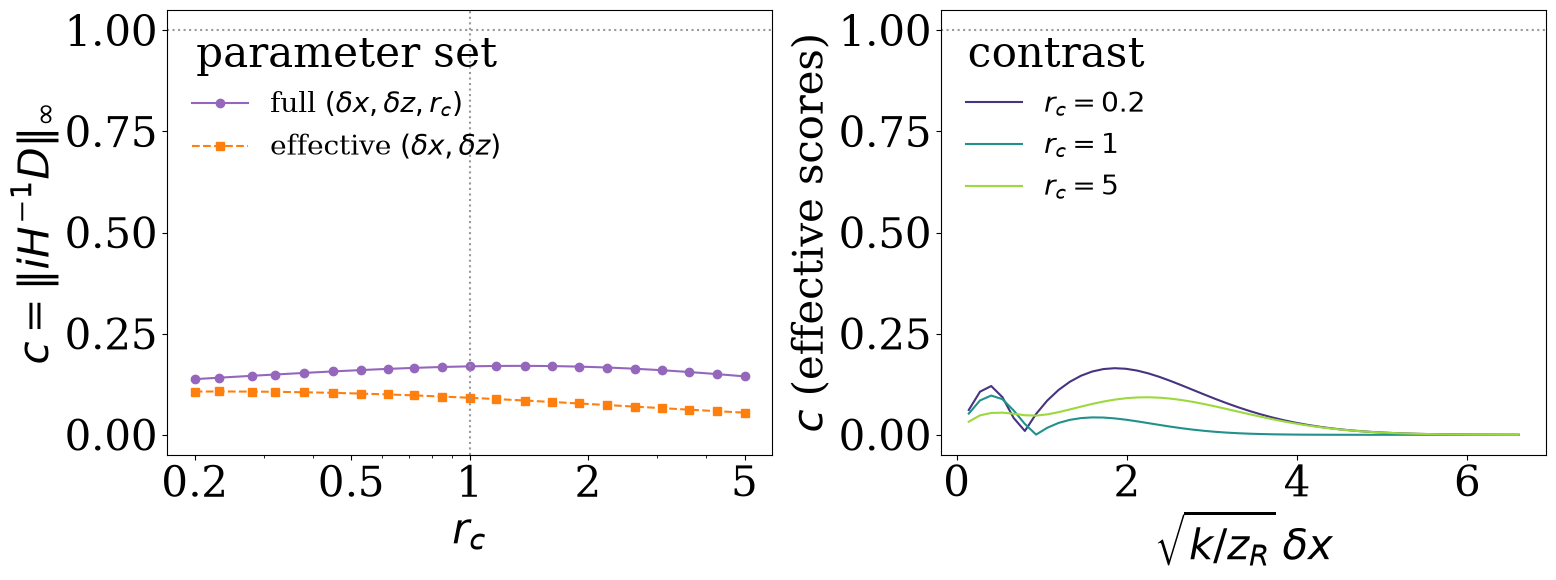

In [11]:
def _incompat(h: np.ndarray, d: np.ndarray) -> np.ndarray:
    """C = ||i H^-1 D||_inf per grid point, nan where H is singular."""
    c = np.full(h.shape[:-2], np.nan)
    mask = np.linalg.cond(h) < 1e12
    x = np.linalg.solve(h[mask], d[mask])
    c[mask] = np.abs(np.linalg.eigvals(1j * x)).max(axis=-1)
    return c


def _effective_blocks(h: np.ndarray, d: np.ndarray) -> tuple[np.ndarray, np.ndarray]:
    """Marginal 2x2 QFIM and effective-score compatibility, r_c marginalised."""
    k = h[..., :2, 2] / h[..., 2, 2][..., None]  # k_a = H_ar / H_rr
    h_marg = h[..., :2, :2] - k[..., :, None] * h[..., 2, :2][..., None, :]
    # D_eff_ab = D_ab - k_b D_ar - k_a D_rb (D_rr = 0); one free entry in 2x2.
    d01 = d[..., 0, 1] - k[..., 1] * d[..., 0, 2] + k[..., 0] * d[..., 1, 2]
    d_eff = np.zeros(h_marg.shape)
    d_eff[..., 0, 1] = d01
    d_eff[..., 1, 0] = -d01
    return h_marg, d_eff


c_full = [_incompat(h, d) for h, d in zip(qfis, compats, strict=False)]
c_eff = [
    _incompat(*_effective_blocks(h, d)) for h, d in zip(qfis, compats, strict=False)
]

fig, axes = plt.subplots(1, 2, figsize=(16, 6.5))

axes[0].plot(
    c_arr,
    [c[ix0, iz0] for c in c_full],
    "o-",
    color="tab:purple",
    label=r"full $(\delta x, \delta z, r_c)$",
)
axes[0].plot(
    c_arr,
    [c[ix0, iz0] for c in c_eff],
    "s--",
    color="tab:orange",
    label=r"effective $(\delta x, \delta z)$",
)
axes[0].axvline(1.0, color="0.6", ls=":", lw=1.5)
axes[0].set_xscale("log")
axes[0].set_xticks(r_ticks)
axes[0].xaxis.set_major_formatter(_g)
axes[0].xaxis.set_minor_formatter(NullFormatter())
axes[0].set_xlabel(r"$r_c$")
axes[0].set_ylabel(r"$c = \Vert i H^{-1} D \Vert_{\infty}$")
axes[0].legend(title="parameter set", frameon=False, loc="upper left")

for k_, cval in enumerate(sel_c):
    j = contrasts.index(cval)
    axes[1].plot(
        np.sqrt(2) * x_range,
        c_eff[j][:, iz_w],
        "-",
        color=c_shades[k_],
        label=rf"$r_c={cval:g}$",
    )
axes[1].set_xlabel(r"$\sqrt{k/z_R}\,\delta x$")
axes[1].set_ylabel(r"$c$ (effective scores)")
axes[1].legend(title="contrast", frameon=False, loc="upper left")

for ax in axes:
    ax.axhline(1.0, color="0.6", ls=":", lw=1.5)
    ax.set_ylim(-0.05, 1.05)

fig.tight_layout()
# fig.savefig(f"incompatibility_vs_contrast.{FORMAT}",
# format=FORMAT, bbox_inches="tight")
plt.show()